In [1]:
# LOAD DATASET AND CHECK MISSING VALUES

import pandas as pd
import numpy as np
from pathlib import Path
import hashlib
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Users\hp\Nassau_Candy_Final_Submission")
RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "Nassau Candy Distributor.csv"
PROCESSED_FOLDER = PROJECT_ROOT / "data" / "processed"
FIGURES_FOLDER = PROJECT_ROOT / "reports" / "figures"

PROCESSED_FOLDER.mkdir(parents=True, exist_ok=True)
FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)

if not RAW_CSV_PATH.exists():
    raise FileNotFoundError(f"Original CSV not found: {RAW_CSV_PATH}")

# Record original file hash for later integrity verification
def calculate_file_hash(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

original_file_hash = calculate_file_hash(RAW_CSV_PATH)

# Read original data without modifying the source file
df_raw = pd.read_csv(RAW_CSV_PATH)

# Create an independent working copy
df_quality = df_raw.copy(deep=True)

missing_count = df_quality.isnull().sum()

missing_report = pd.DataFrame({
    "Column": missing_count.index,
    "Missing Values": missing_count.values
})

display(missing_report)

print("Total Missing Values:", missing_count.sum())

,Column,Missing Values
0,Row ID,0
1,Order ID,0
2,Order Date,0
3,Ship Date,0
4,Ship Mode,0
5,Customer ID,0
6,Country/Region,0
7,City,0
8,State/Province,0
9,Postal Code,0


Total Missing Values: 0


In [3]:
# CALCULATE MISSING VALUE PERCENTAGES

missing_percentage = (
    df_quality.isnull().mean() * 100
).round(2)

missing_percentage_report = pd.DataFrame({
    "Column": missing_percentage.index,
    "Missing Percentage": missing_percentage.values
})

display(missing_percentage_report)

,Column,Missing Percentage
0,Row ID,0.0
1,Order ID,0.0
2,Order Date,0.0
3,Ship Date,0.0
4,Ship Mode,0.0
5,Customer ID,0.0
6,Country/Region,0.0
7,City,0.0
8,State/Province,0.0
9,Postal Code,0.0


In [5]:
# IDENTIFY EXACT DUPLICATE ROWS

duplicate_count = df_quality.duplicated().sum()

duplicate_report = pd.DataFrame({
    "Metric": ["Total Records", "Exact Duplicate Rows"],
    "Count": [len(df_quality), duplicate_count]
})

display(duplicate_report)

if duplicate_count == 0:
    print("No exact duplicate rows found.")
else:
    print("Duplicate records require investigation.")
    display(df_quality[df_quality.duplicated(keep=False)].head(20))

,Metric,Count
0,Total Records,10194
1,Exact Duplicate Rows,0


No exact duplicate rows found.


In [7]:
# VALIDATE ROW ID UNIQUENESS

row_id_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Non-Missing Row IDs",
        "Unique Row IDs",
        "Duplicate Row IDs",
        "Missing Row IDs"
    ],
    "Count": [
        len(df_quality),
        df_quality["Row ID"].count(),
        df_quality["Row ID"].nunique(),
        df_quality["Row ID"].duplicated().sum(),
        df_quality["Row ID"].isnull().sum()
    ]
})

display(row_id_report)

,Metric,Count
0,Total Rows,10194
1,Non-Missing Row IDs,10194
2,Unique Row IDs,10194
3,Duplicate Row IDs,0
4,Missing Row IDs,0


In [9]:
# ANALYZE ORDER ID REPETITION AND ORDER STRUCTURE

order_id_counts = df_quality["Order ID"].value_counts(dropna=True)

repeated_orders = order_id_counts[order_id_counts > 1]

order_structure_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Orders",
        "Repeated Order IDs",
        "Records in Repeated Orders",
        "Maximum Lines per Order"
    ],
    "Count": [
        len(df_quality),
        df_quality["Order ID"].nunique(),
        len(repeated_orders),
        repeated_orders.sum(),
        order_id_counts.max() if not order_id_counts.empty else 0
    ]
})

display(order_structure_report)

print("Most Repeated Orders:")
display(repeated_orders.head(10))

,Metric,Count
0,Total Records,10194
1,Unique Orders,8549
2,Repeated Order IDs,1373
3,Records in Repeated Orders,3018
4,Maximum Lines per Order,5


Most Repeated Orders:


Order ID
US-2021-155502-CHO-MIL-31000    5
US-2024-113278-CHO-MIL-31000    5
US-2022-130974-CHO-SCR-58000    5
US-2024-157987-CHO-NUT-13000    5
US-2022-112130-CHO-FUD-51000    5
US-2022-126977-CHO-SCR-58000    5
US-2024-104731-CHO-FUD-51000    5
US-2024-100111-CHO-NUT-13000    5
US-2023-108504-CHO-FUD-51000    4
US-2022-126725-CHO-MIL-31000    4
Name: count, dtype: int64

In [11]:
# VALIDATE CUSTOMER ID COMPLETENESS AND UNIQUENESS

customer_ids = df_quality["Customer ID"].astype("string").str.strip()

customer_id_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Customer IDs",
        "Missing Customer IDs",
        "Blank Customer IDs"
    ],
    "Count": [
        len(df_quality),
        df_quality["Customer ID"].nunique(),
        df_quality["Customer ID"].isnull().sum(),
        customer_ids.eq("").sum()
    ]
})

display(customer_id_report)

,Metric,Count
0,Total Records,10194
1,Unique Customer IDs,5044
2,Missing Customer IDs,0
3,Blank Customer IDs,0


In [13]:
# VALIDATE PRODUCT ID COMPLETENESS AND UNIQUENESS

product_ids = df_quality["Product ID"].astype("string").str.strip()

product_id_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Product IDs",
        "Missing Product IDs",
        "Blank Product IDs"
    ],
    "Count": [
        len(df_quality),
        df_quality["Product ID"].nunique(),
        df_quality["Product ID"].isnull().sum(),
        product_ids.eq("").sum()
    ]
})

display(product_id_report)

,Metric,Count
0,Total Records,10194
1,Unique Product IDs,15
2,Missing Product IDs,0
3,Blank Product IDs,0


In [15]:
# CHECK PRODUCT ID AND PRODUCT NAME CONSISTENCY

product_mapping = (
    df_quality.groupby("Product ID", dropna=False)["Product Name"]
    .nunique(dropna=True)
)

product_name_mapping = (
    df_quality.groupby("Product Name", dropna=False)["Product ID"]
    .nunique(dropna=True)
)

product_validation_report = pd.DataFrame({
    "Metric": [
        "Unique Product IDs",
        "Unique Product Names",
        "Product IDs with Multiple Names",
        "Product Names with Multiple IDs"
    ],
    "Count": [
        df_quality["Product ID"].nunique(),
        df_quality["Product Name"].nunique(),
        (product_mapping > 1).sum(),
        (product_name_mapping > 1).sum()
    ]
})

display(product_validation_report)

print("Product ID Mapping Conflicts:")
display(product_mapping[product_mapping > 1])

print("Product Name Mapping Conflicts:")
display(product_name_mapping[product_name_mapping > 1])

,Metric,Count
0,Unique Product IDs,15
1,Unique Product Names,15
2,Product IDs with Multiple Names,0
3,Product Names with Multiple IDs,0


Product ID Mapping Conflicts:


Series([], Name: Product Name, dtype: int64)

Product Name Mapping Conflicts:


Series([], Name: Product ID, dtype: int64)

In [17]:
# VALIDATE ZERO AND NEGATIVE SALES VALUES

sales_values = pd.to_numeric(df_quality["Sales"], errors="coerce")

sales_validation = pd.DataFrame({
    "Metric": [
        "Missing Values",
        "Invalid Numeric Values",
        "Zero Sales",
        "Negative Sales",
        "Positive Sales"
    ],
    "Count": [
        df_quality["Sales"].isnull().sum(),
        (df_quality["Sales"].notna() & sales_values.isna()).sum(),
        (sales_values == 0).sum(),
        (sales_values < 0).sum(),
        (sales_values > 0).sum()
    ]
})

display(sales_validation)

,Metric,Count
0,Missing Values,0
1,Invalid Numeric Values,0
2,Zero Sales,0
3,Negative Sales,0
4,Positive Sales,10194


In [19]:
# VALIDATE ZERO AND NEGATIVE UNIT VALUES

unit_values = pd.to_numeric(df_quality["Units"], errors="coerce")

units_validation = pd.DataFrame({
    "Metric": [
        "Missing Values",
        "Invalid Numeric Values",
        "Zero Units",
        "Negative Units",
        "Positive Units"
    ],
    "Count": [
        df_quality["Units"].isnull().sum(),
        (df_quality["Units"].notna() & unit_values.isna()).sum(),
        (unit_values == 0).sum(),
        (unit_values < 0).sum(),
        (unit_values > 0).sum()
    ]
})

display(units_validation)

,Metric,Count
0,Missing Values,0
1,Invalid Numeric Values,0
2,Zero Units,0
3,Negative Units,0
4,Positive Units,10194


In [21]:
# VALIDATE ZERO AND NEGATIVE COST VALUES

cost_values = pd.to_numeric(df_quality["Cost"], errors="coerce")

cost_validation = pd.DataFrame({
    "Metric": [
        "Missing Values",
        "Invalid Numeric Values",
        "Zero Cost",
        "Negative Cost",
        "Positive Cost"
    ],
    "Count": [
        df_quality["Cost"].isnull().sum(),
        (df_quality["Cost"].notna() & cost_values.isna()).sum(),
        (cost_values == 0).sum(),
        (cost_values < 0).sum(),
        (cost_values > 0).sum()
    ]
})

display(cost_validation)

,Metric,Count
0,Missing Values,0
1,Invalid Numeric Values,0
2,Zero Cost,0
3,Negative Cost,0
4,Positive Cost,10194


In [23]:
# VALIDATE ZERO AND NEGATIVE GROSS PROFIT VALUES

profit_values = pd.to_numeric(
    df_quality["Gross Profit"], errors="coerce"
)

profit_validation = pd.DataFrame({
    "Metric": [
        "Missing Values",
        "Invalid Numeric Values",
        "Zero Gross Profit",
        "Negative Gross Profit",
        "Positive Gross Profit"
    ],
    "Count": [
        df_quality["Gross Profit"].isnull().sum(),
        (df_quality["Gross Profit"].notna() & profit_values.isna()).sum(),
        (profit_values == 0).sum(),
        (profit_values < 0).sum(),
        (profit_values > 0).sum()
    ]
})

display(profit_validation)

,Metric,Count
0,Missing Values,0
1,Invalid Numeric Values,0
2,Zero Gross Profit,0
3,Negative Gross Profit,0
4,Positive Gross Profit,10194


In [25]:
# INSPECT ORIGINAL DATE VALUES WITHOUT MODIFYING THEM

date_format_report = []

for column in ["Order Date", "Ship Date"]:
    original_dates = df_raw[column].dropna().astype(str).str.strip()

    date_format_report.append({
        "Column": column,
        "Non-Missing Values": len(original_dates),
        "Unique Original Formats": original_dates.str.len().nunique(),
        "Sample Original Values": original_dates.head(5).tolist(),
        "Empty Strings": original_dates.eq("").sum()
    })

date_format_report = pd.DataFrame(date_format_report)

display(date_format_report)

print("Original date columns remain unchanged in df_raw.")

,Column,Non-Missing Values,Unique Original Formats,Sample Original Values,Empty Strings
0,Order Date,10194,1,"[03-01-2024, 04-01-2024, 04-01-2024, 04-01-202...",0
1,Ship Date,10194,1,"[30-06-2026, 01-07-2026, 01-07-2026, 01-07-202...",0


Original date columns remain unchanged in df_raw.


In [27]:
# PARSE ORDER DATE SEPARATELY IN A NEW SERIES

order_date_parsed = pd.to_datetime(
    df_raw["Order Date"],
    dayfirst=True,
    errors="coerce"
)

print("Order Date Parsing Completed.")
print("Successfully Parsed:", order_date_parsed.notna().sum())
print("Unparsed Values:", order_date_parsed.isna().sum())

display(pd.DataFrame({
    "Original Order Date": df_raw["Order Date"].head(10),
    "Parsed Order Date": order_date_parsed.head(10)
}))

Order Date Parsing Completed.
Successfully Parsed: 10194
Unparsed Values: 0


,Original Order Date,Parsed Order Date
0,03-01-2024,2024-01-03
1,04-01-2024,2024-01-04
2,04-01-2024,2024-01-04
3,04-01-2024,2024-01-04
4,05-01-2024,2024-01-05
5,06-01-2024,2024-01-06
6,06-01-2024,2024-01-06
7,06-01-2024,2024-01-06
8,06-01-2024,2024-01-06
9,06-01-2024,2024-01-06


In [29]:
# PARSE SHIP DATE SEPARATELY IN A NEW SERIES

ship_date_parsed = pd.to_datetime(
    df_raw["Ship Date"],
    dayfirst=True,
    errors="coerce"
)

print("Ship Date Parsing Completed.")
print("Successfully Parsed:", ship_date_parsed.notna().sum())
print("Unparsed Values:", ship_date_parsed.isna().sum())

display(pd.DataFrame({
    "Original Ship Date": df_raw["Ship Date"].head(10),
    "Parsed Ship Date": ship_date_parsed.head(10)
}))

Ship Date Parsing Completed.
Successfully Parsed: 10194
Unparsed Values: 0


,Original Ship Date,Parsed Ship Date
0,30-06-2026,2026-06-30
1,01-07-2026,2026-07-01
2,01-07-2026,2026-07-01
3,01-07-2026,2026-07-01
4,05-07-2026,2026-07-05
5,03-07-2026,2026-07-03
6,03-07-2026,2026-07-03
7,30-06-2026,2026-06-30
8,03-07-2026,2026-07-03
9,03-07-2026,2026-07-03


In [31]:
# IDENTIFY DATE PARSING FAILURES

order_date_failures = (
    df_raw["Order Date"].notna() & order_date_parsed.isna()
)

ship_date_failures = (
    df_raw["Ship Date"].notna() & ship_date_parsed.isna()
)

date_failure_report = pd.DataFrame({
    "Column": ["Order Date", "Ship Date"],
    "Parsing Failures": [
        order_date_failures.sum(),
        ship_date_failures.sum()
    ],
    "Missing Original Values": [
        df_raw["Order Date"].isnull().sum(),
        df_raw["Ship Date"].isnull().sum()
    ]
})

display(date_failure_report)

print("Order Date Parsing Failure Examples:")
display(df_raw.loc[order_date_failures, ["Order Date"]].head(10))

print("Ship Date Parsing Failure Examples:")
display(df_raw.loc[ship_date_failures, ["Ship Date"]].head(10))

,Column,Parsing Failures,Missing Original Values
0,Order Date,0,0
1,Ship Date,0,0


Order Date Parsing Failure Examples:


,Order Date


Ship Date Parsing Failure Examples:


,Ship Date


In [33]:
# VALIDATE ORDER AND SHIP DATE CHRONOLOGY

date_validation = pd.DataFrame({
    "Order Date": order_date_parsed,
    "Ship Date": ship_date_parsed
})

date_validation["Ship Before Order"] = (
    date_validation["Ship Date"] < date_validation["Order Date"]
)

date_validation["Chronology Valid"] = (
    date_validation["Ship Date"] >= date_validation["Order Date"]
)

print(
    "Ship Dates Earlier Than Order Dates:",
    date_validation["Ship Before Order"].sum()
)

print("\nChronology Issue Records:")
display(
    date_validation[date_validation["Ship Before Order"]].head(20)
)

Ship Dates Earlier Than Order Dates: 0

Chronology Issue Records:


,Order Date,Ship Date,Ship Before Order,Chronology Valid


In [35]:
# CALCULATE AND INSPECT SHIPPING LEAD TIME

date_validation["Lead Time Days"] = (
    date_validation["Ship Date"] - date_validation["Order Date"]
).dt.days

lead_time = date_validation["Lead Time Days"].dropna()

lead_time_report = lead_time.describe().to_frame(
    name="Lead Time Days"
)

display(lead_time_report)

print("Negative Lead Times:", (lead_time < 0).sum())
print("Zero Lead Times:", (lead_time == 0).sum())
print("Maximum Lead Time:", lead_time.max())

,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000


Negative Lead Times: 0
Zero Lead Times: 0
Maximum Lead Time: 1642


In [37]:
# DETECT OUTLIERS USING THE INTERQUARTILE RANGE METHOD

outlier_columns = ["Sales", "Units", "Cost", "Gross Profit"]

outlier_records = []
outlier_masks = {}

for column in outlier_columns:
    values = pd.to_numeric(df_raw[column], errors="coerce")

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - (1.5 * iqr)
    upper_limit = q3 + (1.5 * iqr)

    mask = (values < lower_limit) | (values > upper_limit)
    outlier_masks[column] = mask.fillna(False)

    outlier_records.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": mask.sum(),
        "Outlier Percentage": round(mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_records)

display(outlier_report)

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,Sales,7.2,18.00,10.80,-9.000,34.200,245,2.40
1,Units,2.0,5.00,3.00,-2.500,9.500,175,1.72
2,Cost,2.4,5.70,3.30,-2.550,10.650,397,3.89
3,Gross Profit,4.9,12.25,7.35,-6.125,23.275,217,2.13


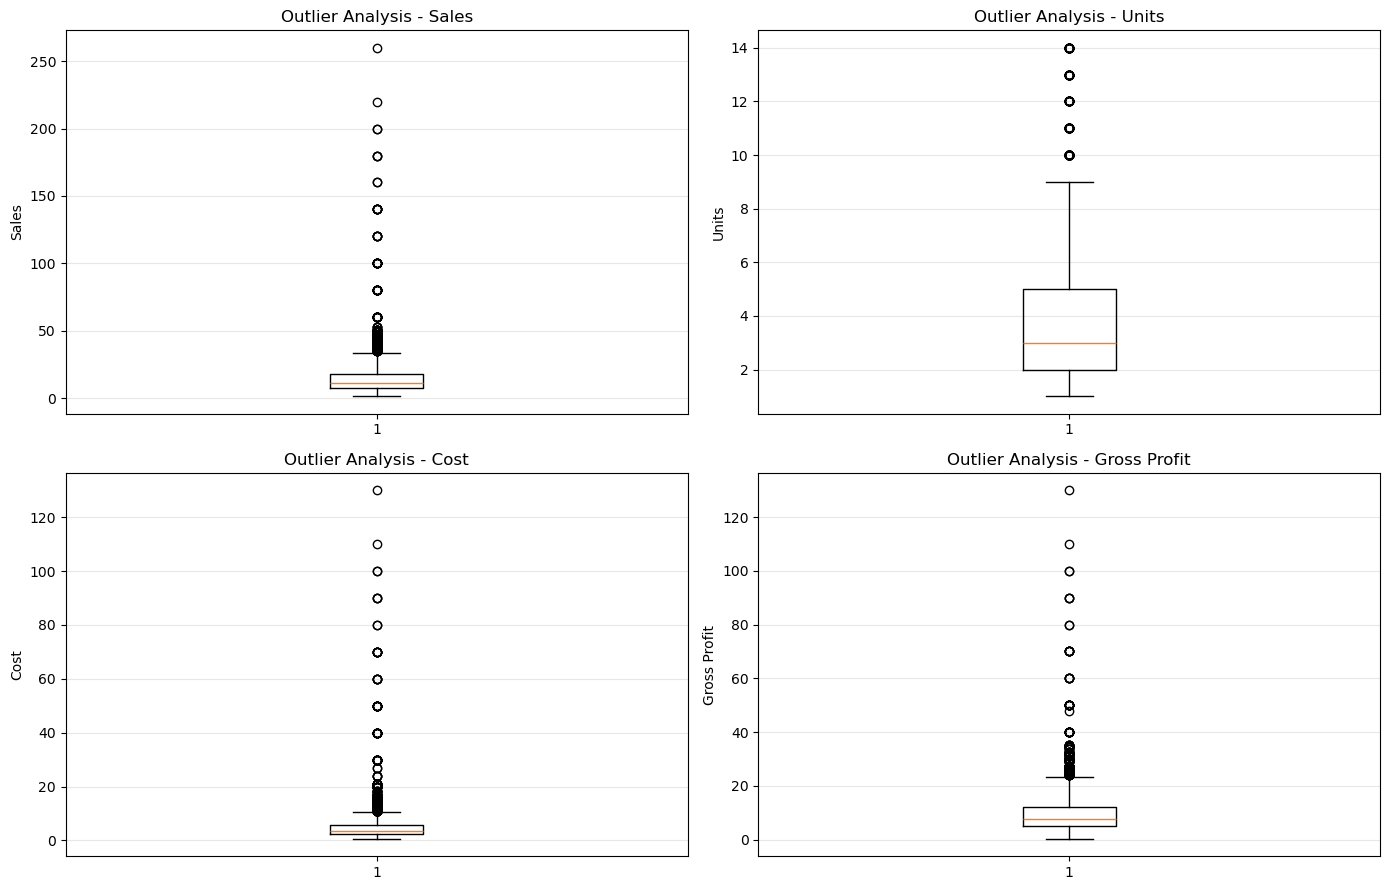

Boxplots saved to: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\phase_02_outlier_boxplots.png


In [39]:
# CREATE BOXPLOTS FOR NUMERICAL OUTLIER VISUALIZATION

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flatten(), outlier_columns):
    values = pd.to_numeric(df_raw[column], errors="coerce").dropna()

    ax.boxplot(values)
    ax.set_title(f"Outlier Analysis - {column}")
    ax.set_ylabel(column)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

boxplot_path = FIGURES_FOLDER / "phase_02_outlier_boxplots.png"

plt.savefig(boxplot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Boxplots saved to:", boxplot_path)

In [41]:
# ANALYZE THE IMPACT OF OUTLIERS ON NUMERICAL VALUES

outlier_impact_records = []

for column in outlier_columns:
    values = pd.to_numeric(df_raw[column], errors="coerce")
    mask = outlier_masks[column]

    total_value = values.sum()
    outlier_value = values[mask].sum()

    absolute_total = values.abs().sum()
    absolute_outlier_total = values[mask].abs().sum()

    outlier_impact_records.append({
        "Column": column,
        "Total Records": values.notna().sum(),
        "Outlier Records": mask.sum(),
        "Outlier Value Total": outlier_value,
        "Overall Value Total": total_value,
        "Outlier Share of Absolute Value (%)": round(
            absolute_outlier_total / absolute_total * 100, 2
        ) if absolute_total else 0
    })

outlier_impact_report = pd.DataFrame(outlier_impact_records)

display(outlier_impact_report)

,Column,Total Records,Outlier Records,Outlier Value Total,Overall Value Total,Outlier Share of Absolute Value (%)
0,Sales,10194,245,14266.50,141783.63,10.06
1,Units,10194,175,2031.00,38654.00,5.25
2,Cost,10194,397,7973.92,48340.83,16.50
3,Gross Profit,10194,217,7698.52,93442.80,8.24


In [43]:
# GENERATE DATA QUALITY PASS AND WARNING REPORT

quality_checks = [
    ("Missing Values", df_raw.isnull().sum().sum()),
    ("Exact Duplicate Rows", df_raw.duplicated().sum()),
    ("Duplicate Row IDs", df_raw["Row ID"].duplicated().sum()),
    ("Missing Customer IDs", df_raw["Customer ID"].isnull().sum()),
    ("Blank Customer IDs", df_raw["Customer ID"].astype("string").str.strip().eq("").sum()),
    ("Missing Product IDs", df_raw["Product ID"].isnull().sum()),
    ("Blank Product IDs", df_raw["Product ID"].astype("string").str.strip().eq("").sum()),
    ("Product ID Mapping Conflicts", (product_mapping > 1).sum()),
    ("Product Name Mapping Conflicts", (product_name_mapping > 1).sum()),
    ("Negative Sales", (sales_values < 0).sum()),
    ("Zero Sales", (sales_values == 0).sum()),
    ("Negative Units", (unit_values < 0).sum()),
    ("Zero Units", (unit_values == 0).sum()),
    ("Negative Cost", (cost_values < 0).sum()),
    ("Zero Cost", (cost_values == 0).sum()),
    ("Negative Gross Profit", (profit_values < 0).sum()),
    ("Zero Gross Profit", (profit_values == 0).sum()),
    ("Order Date Parsing Failures", order_date_failures.sum()),
    ("Ship Date Parsing Failures", ship_date_failures.sum()),
    ("Ship Before Order", date_validation["Ship Before Order"].sum()),
    ("Negative Lead Time", (lead_time < 0).sum()),
    ("Numerical Outlier Records", outlier_report["Outlier Count"].sum())
]

quality_signoff = pd.DataFrame(
    quality_checks,
    columns=["Quality Check", "Issue Count"]
)

# Outliers and zero values are warnings, not automatic failures.
warning_checks = {
    "Zero Sales",
    "Zero Units",
    "Zero Cost",
    "Zero Gross Profit",
    "Numerical Outlier Records"
}

quality_signoff["Status"] = quality_signoff.apply(
    lambda row: (
        "WARNING"
        if row["Issue Count"] > 0 and row["Quality Check"] in warning_checks
        else "PASS"
        if row["Issue Count"] == 0
        else "REVIEW"
    ),
    axis=1
)

display(quality_signoff)

print("\nQUALITY SIGN-OFF SUMMARY")
print(quality_signoff["Status"].value_counts())

quality_report_path = (
    PROCESSED_FOLDER / "Nassau_Candy_Quality_Signoff.csv"
)

quality_signoff.to_csv(quality_report_path, index=False)

print("\nQuality Sign-off saved to:", quality_report_path)

,Quality Check,Issue Count,Status
0,Missing Values,0,PASS
1,Exact Duplicate Rows,0,PASS
2,Duplicate Row IDs,0,PASS
3,Missing Customer IDs,0,PASS
4,Blank Customer IDs,0,PASS
5,Missing Product IDs,0,PASS
6,Blank Product IDs,0,PASS
7,Product ID Mapping Conflicts,0,PASS
8,Product Name Mapping Conflicts,0,PASS
9,Negative Sales,0,PASS



QUALITY SIGN-OFF SUMMARY
Status
PASS       21
WARNING     1
Name: count, dtype: int64

Quality Sign-off saved to: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\Nassau_Candy_Quality_Signoff.csv


In [45]:
# VERIFY ORIGINAL RAW CSV INTEGRITY

current_file_hash = calculate_file_hash(RAW_CSV_PATH)

integrity_report = pd.DataFrame({
    "Metric": [
        "Original CSV Exists",
        "Original File Hash Before Analysis",
        "Original File Hash After Analysis",
        "Original File Unchanged",
        "Original DataFrame Row Count",
        "Current Original DataFrame Row Count",
        "Original DataFrame Unchanged"
    ],
    "Result": [
        RAW_CSV_PATH.exists(),
        original_file_hash,
        current_file_hash,
        original_file_hash == current_file_hash,
        len(df_raw),
        len(pd.read_csv(RAW_CSV_PATH)),
        df_raw.equals(pd.read_csv(RAW_CSV_PATH))
    ]
})

display(integrity_report)

if original_file_hash == current_file_hash:
    print("SUCCESS: ORIGINAL CSV FILE IS UNCHANGED!")
else:
    print("WARNING: ORIGINAL CSV HASH HAS CHANGED. INVESTIGATION REQUIRED.")

,Metric,Result
0,Original CSV Exists,True
1,Original File Hash Before Analysis,6ae9208e77ce410e90073b19813d29f89853ce9f3cce43...
2,Original File Hash After Analysis,6ae9208e77ce410e90073b19813d29f89853ce9f3cce43...
3,Original File Unchanged,True
4,Original DataFrame Row Count,10194
5,Current Original DataFrame Row Count,10194
6,Original DataFrame Unchanged,True


SUCCESS: ORIGINAL CSV FILE IS UNCHANGED!
